# Comparação entre as versões do dataset

Este notebook compara a versão 1 (`dataset/v1`, uma execução do cenário `evento_termico_v1`) com a versão 2
(`dataset/v2`, oito execuções do cenário `evento_termico_v2`) e responde às perguntas de revisão do cenário:

1. Há exemplos suficientes em cada classe?
2. Os rótulos fazem sentido?
3. O cenário está fácil ou artificial demais?
4. Os modelos aprendem algo relevante ou apenas uma regra trivial?

As mudanças da v2 e sua justificativa estão em `cenarios/v2/cenarios.md`.

In [1]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import LeaveOneGroupOut, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

from comum import (CLASSES, COR_CLASSE, DATASETS, NOMES_CLASSES, REDE, RESULTADOS, SENSORES, SEQUENCIAL, TAXA_BATERIA,
                   TEXTO_SEC, aplicar_estilo, carregar_dados, salvar)

aplicar_estilo()
pd.set_option("display.precision", 3)
SEMENTE = 42
RESULTADOS.mkdir(exist_ok=True)

dados = {v: carregar_dados(v) for v in ("v1", "v2")}
brutos = {v: carregar_dados(v, incluir_cruzamentos=True) for v in ("v1", "v2")}
registros = {v: json.loads((DATASETS / v / "execucao.json").read_text(encoding="utf-8")) for v in ("v1", "v2")}
for v in dados:
    print(v, registros[v]["status"], "|", registros[v]["runs"], "execução(ões) |", len(brutos[v]), "linhas |",
          len(dados[v]), "sem cruzamentos de fase")

v1 concluida | 1 execução(ões) | 2062 linhas | 2060 sem cruzamentos de fase
v2 concluida | 8 execução(ões) | 17812 linhas | 17796 sem cruzamentos de fase


## 1. Tabela comparativa das versões

In [2]:
def resumo_versao(v):
    d, reg = brutos[v], registros[v]
    execs = reg["executions"]
    primeira_carga = d[d["available"] == 1].sort_values("sent_time_ns").groupby(["run_id", "device_id"])["battery"].first()
    papeis = pd.Series(dtype=float)
    for e in execs:
        papeis = papeis.add(pd.Series(e["roles"]), fill_value=0)
    linha = {
        "Cenário": reg["scenario_id"],
        "Execuções (com desastre / sem desastre)": f"{sum(len(e['phases']) > 1 for e in execs)} / {sum(len(e['phases']) == 1 for e in execs)}",
        "Sensores por execução": f"{min(e['devices'] for e in execs)}–{max(e['devices'] for e in execs)}",
        "Duração do ciclo (s)": f"{min(e['duration_s'] for e in execs):.0f}–{max(e['duration_s'] for e in execs):.0f}",
        "Carga na 1ª leitura (%)": f"{primeira_carga.min():.0f}–{primeira_carga.max():.0f}",
        "Papéis (controle / degradação / energia / rede)": " / ".join(str(int(papeis.get(p, 0))) for p in
                                                                     ("controle", "degradacao", "falha_energetica", "falha_rede")),
        "Perturbações benignas": int(sum(e["events_logged_by_devices"].get(n, 0) for e in execs
                                         for n in ("congestionamento_benigno", "aquecimento_local_benigno"))),
        "Tentativas": len(d),
        "Cruzaram fronteira de fase": int(d["cruzou_fase"].sum()),
        "Disponibilidade geral": f"{100 * d['available'].mean():.1f}%".replace(".", ","),
    }
    for c in CLASSES:
        sel = d[d["label"] == c]
        linha[f"{NOMES_CLASSES[c]}: tentativas (%)"] = f"{len(sel)} ({100 * len(sel) / len(d):.1f}%)".replace(".", ",")
        linha[f"{NOMES_CLASSES[c]}: disponibilidade"] = f"{100 * sel['available'].mean():.1f}%".replace(".", ",")
    linha["Colunas"] = d.shape[1] - 1
    return linha

comparacao = pd.DataFrame({"Versão 1": resumo_versao("v1"), "Versão 2": resumo_versao("v2")})
comparacao.to_csv(RESULTADOS / "comparacao_versoes.csv")
comparacao

,Versão 1,Versão 2
Cenário,evento_termico_v1,evento_termico_v2
Execuções (com desastre / sem desastre),1 / 0,7 / 1
Sensores por execução,10–10,8–12
Duração do ciclo (s),1200–1200,1110–1320
Carga na 1ª leitura (%),94–100,60–100
Papéis (controle / degradação / energia / rede),2 / 4 / 2 / 2,38 / 30 / 7 / 8
Perturbações benignas,0,15
Tentativas,2062,17812
Cruzaram fronteira de fase,2,16
Disponibilidade geral,"82,3%","89,8%"


In [3]:
# Exemplos por classe em cada execução da v2.
por_execucao = pd.crosstab(brutos["v2"]["run_id"].str[:11], brutos["v2"]["label"]).reindex(columns=CLASSES, fill_value=0)
por_execucao["disponibilidade"] = brutos["v2"].groupby(brutos["v2"]["run_id"].str[:11])["available"].mean().round(3)
por_execucao

label,normal,pre_desastre,desastre,pos_desastre,disponibilidade
run_id,,,,,
execucao_01,688,528,452,452,0.877
execucao_02,520,574,554,656,0.905
execucao_03,365,399,433,393,0.825
execucao_04,640,682,620,540,0.913
execucao_05,518,536,505,561,0.854
execucao_06,635,602,614,587,0.915
execucao_07,708,434,503,538,0.869
execucao_08,2575,0,0,0,0.988


**Exemplos e rótulos.**

- **Tamanho.** A v2 tem 8,6 vezes mais linhas (17.812 contra 2.062), e cada classe tem pelo menos 3.681 exemplos (21%). A classe `normal` ficou maior (37%) por causa da execução sem desastre (2.575 linhas) e das fases normais mais longas em algumas execuções. Dentro de cada execução com desastre, as classes têm de 365 a 708 linhas, sem desequilíbrio grave.
- **Verificações.** As oito execuções passaram em todas as verificações: eventos aceitos e registrados pelos sensores em até 0,37 s, falhas energéticas e de rede com os efeitos previstos, controles estáveis e nenhuma tentativa perdida dentro do ciclo. Os rótulos, portanto, correspondem ao roteiro executado. Apenas 16 respostas atravessaram uma fronteira de fase.
- **Disponibilidade.** É maior na v2 (90% contra 82%) porque a proporção de sensores com falha energética caiu (7 de 83, contra 2 de 10) e a descarga no desastre foi reduzida.

## 2. A bateria ainda indica a fase?

Na v1, todos os sensores começam com carga parecida e a perdem no mesmo ritmo, então o nível de bateria acompanha o
tempo. A figura compara a distribuição da carga por classe nas duas versões, e a taxa de descarga observada
(`battery_rate_pp_min`) na v2.

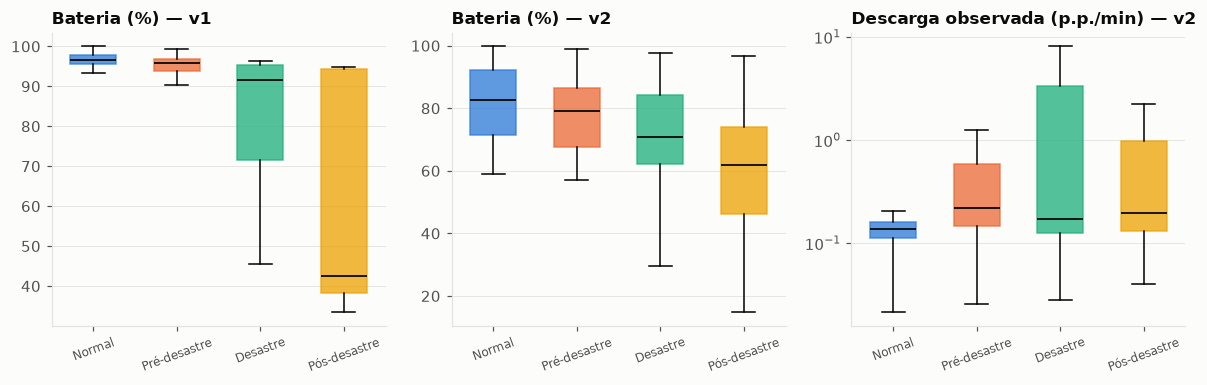

In [4]:
fig, eixos = plt.subplots(1, 3, figsize=(11, 3.6))
rotulos = [NOMES_CLASSES[c] for c in CLASSES]
paineis = [("v1", "battery", "Bateria (%) — v1"), ("v2", "battery", "Bateria (%) — v2"),
           ("v2", "battery_rate_pp_min", "Descarga observada (p.p./min) — v2")]
for ax, (v, coluna, titulo) in zip(eixos, paineis):
    grupos = [dados[v].loc[dados[v]["label"] == c, coluna].dropna() for c in CLASSES]
    caixa = ax.boxplot(grupos, tick_labels=rotulos, patch_artist=True, widths=0.55, showfliers=False,
                       medianprops={"color": "#0b0b0b", "lw": 1.2})
    for patch, c in zip(caixa["boxes"], CLASSES):
        patch.set(facecolor=COR_CLASSE[c], alpha=0.75, edgecolor=COR_CLASSE[c])
    ax.set_title(titulo)
    ax.tick_params(axis="x", labelsize=8, rotation=20)
    ax.grid(axis="x", visible=False)
eixos[2].set_yscale("symlog", linthresh=0.1)
fig.tight_layout()
salvar(fig, "versoes_bateria.png")
plt.show()

Na v1, o nível de bateria separa as classes quase sem sobreposição no início do ciclo: normal e pré-desastre ficam acima de 90%, e o pós-desastre cai para cerca de 40%. Na v2, como a carga inicial varia entre 60% e 100%, as caixas das quatro classes se sobrepõem amplamente; o nível ainda desce ao longo do ciclo, mas não indica mais a fase de um sensor desconhecido. A **taxa de descarga** muda com a fase por outro motivo: o consumo configurado aumenta no pré-desastre e no desastre. Ela é baixa e estreita no normal e mais alta e dispersa nas demais fases, o que a torna um sinal ligado ao fenômeno, e não ao tempo decorrido.

## 3. Avaliação separando execuções inteiras

Na v1, o melhor protocolo disponível era treinar em um gateway e testar no outro, dentro da mesma execução. Na v2, o
protocolo principal é **deixar uma execução de fora por vez** (*leave-one-run-out*): o modelo é treinado com sete
execuções e testado na oitava, que ele nunca viu, e as previsões das oito rodadas são reunidas. Isso mede o que
interessa: o desempenho em uma ocorrência nova do cenário.

Os conjuntos de atributos incluem a bateria de duas formas: o **nível** (`battery`) e a **taxa de descarga observada**
(`battery_rate_pp_min`). O pré-processamento é o mesmo do notebook de modelos (mediana do treino e padronização dentro
de um *pipeline*), e os hiperparâmetros também.

In [5]:
MODELOS = {
    "Árvore de Decisão": DecisionTreeClassifier(min_samples_leaf=5, random_state=SEMENTE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEMENTE, n_jobs=-1),
    "Regressão Logística": LogisticRegression(max_iter=5000),
    "KNN": KNeighborsClassifier(n_neighbors=15),
}
CONJUNTOS_V = {
    "Sensores": SENSORES,
    "Sensores + rede": SENSORES + REDE,
    "Sensores + bateria (nível)": SENSORES + ["battery"],
    "Sensores + bateria (taxa)": SENSORES + TAXA_BATERIA,
    "Sensores + rede + bateria (nível)": SENSORES + REDE + ["battery"],
    "Sensores + rede + bateria (taxa)": SENSORES + REDE + TAXA_BATERIA,
    "Apenas bateria (nível)": ["battery"],
    "Apenas bateria (taxa)": TAXA_BATERIA,
}


def divisoes(v, protocolo):
    d = dados[v]
    if protocolo == "Por gateway":
        return [(d.index[d["gateway_id"] == a], d.index[d["gateway_id"] == b]) for a, b in (("gw01", "gw02"), ("gw02", "gw01"))]
    if protocolo == "Uma execução de fora":
        return [(d.index[tr], d.index[te]) for tr, te in LeaveOneGroupOut().split(d, groups=d["run_id"])]
    tr, te = train_test_split(d.index, test_size=0.3, stratify=d["label"], random_state=SEMENTE)
    return [(tr, te)]


def prever(v, protocolo, atributos, modelo):
    d, y = dados[v], dados[v]["label"].astype(str)
    partes = []
    for tr, te in divisoes(v, protocolo):
        pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), clone(modelo))
        pipe.fit(d.loc[tr, atributos], y[tr])
        partes.append(pd.Series(pipe.predict(d.loc[te, atributos]), index=te))
    return pd.concat(partes).sort_index()


AVALIACOES = [("v1", "Por gateway"), ("v2", "Uma execução de fora")]
resultados, previsoes = [], {}
for v, protocolo in AVALIACOES:
    y = dados[v]["label"].astype(str)
    for conjunto, atributos in CONJUNTOS_V.items():
        for nome, modelo in MODELOS.items():
            prev = prever(v, protocolo, atributos, modelo)
            previsoes[(v, conjunto, nome)] = prev
            resultados.append({"versão": v, "protocolo": protocolo, "conjunto": conjunto, "modelo": nome,
                               "F1 (macro)": f1_score(y[prev.index], prev, average="macro"),
                               "acurácia": accuracy_score(y[prev.index], prev)})
resultados = pd.DataFrame(resultados)
resultados.to_csv(RESULTADOS / "versoes_conjuntos_atributos.csv", index=False, float_format="%.4f")
(resultados.pivot_table(index="conjunto", columns=["versão", "modelo"], values="F1 (macro)")
 .reindex(index=list(CONJUNTOS_V)).round(3))

versão                                v1                                    \
modelo                               KNN Random Forest Regressão Logística   
conjunto                                                                     
Sensores                           0.344         0.423               0.343   
Sensores + rede                    0.493         0.543               0.562   
Sensores + bateria (nível)         0.495         0.720               0.493   
Sensores + bateria (taxa)          0.412         0.668               0.410   
Sensores + rede + bateria (nível)  0.607         0.796               0.633   
Sensores + rede + bateria (taxa)   0.512         0.729               0.586   
Apenas bateria (nível)             0.659         0.711               0.394   
Apenas bateria (taxa)              0.576         0.632               0.473   

versão                                                  v2                \
modelo                            Árvore de Decisão    KNN Random Forest   
conjunto                                                                   
Sensores                                      0.389  0.289         0.331   
Sensores + rede                               0.512  0.419         0.443   
Sensores + bateria (nível)                    0.723  0.383         0.422   
Sensores + bateria (taxa)                     0.673  0.428         0.498   
Sensores + rede + bateria (nível)             0.783  0.491         0.503   
Sensores + rede + bateria (taxa)              0.680  0.473         0.548   
Apenas bateria (nível)                        0.709  0.287         0.336   
Apenas bateria (taxa)                         0.618  0.432         0.397   

versão                                                                   
modelo                            Regressão Logística Árvore de Decisão  
conjunto                                                                 
Sensores                                        0.217             0.323  
Sensores + rede                                 0.437             0.402  
Sensores + bateria (nível)                      0.348             0.392  
Sensores + bateria (taxa)                       0.386             0.468  
Sensores + rede + bateria (nível)               0.495             0.448  
Sensores + rede + bateria (taxa)                0.504             0.493  
Apenas bateria (nível)                          0.250             0.337  
Apenas bateria (taxa)                           0.381             0.401

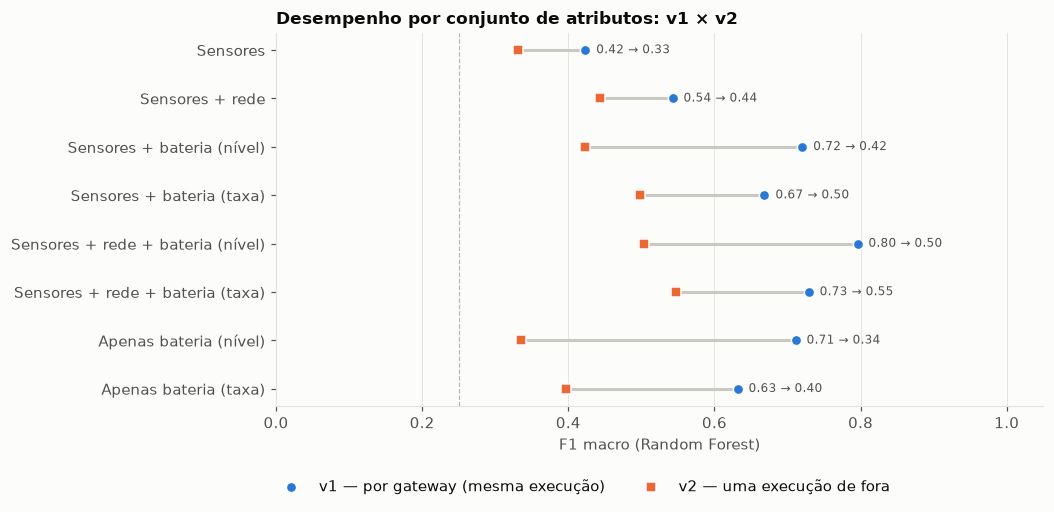

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.4))
rf = resultados[resultados["modelo"] == "Random Forest"].pivot(index="conjunto", columns="versão", values="F1 (macro)")
rf = rf.reindex(list(CONJUNTOS_V))
pos = np.arange(len(rf))
ax.hlines(pos, rf["v1"], rf["v2"], color="#c9c8c2", lw=2, zorder=1)
ax.scatter(rf["v1"], pos, color="#2a78d6", s=45, zorder=3, label="v1 — por gateway (mesma execução)", edgecolor="#fcfcfb")
ax.scatter(rf["v2"], pos, color="#eb6834", s=45, zorder=3, marker="s", label="v2 — uma execução de fora", edgecolor="#fcfcfb")
for i, (a, b) in enumerate(zip(rf["v1"], rf["v2"])):
    ax.text(max(a, b) + 0.015, i, f"{a:.2f} → {b:.2f}", va="center", fontsize=8, color=TEXTO_SEC)
ax.set_yticks(pos, rf.index)
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.axvline(0.25, color="#b8b7b1", lw=0.8, ls="--")
ax.set_xlabel("F1 macro (Random Forest)")
ax.grid(axis="y", visible=False)
ax.set_title("Desempenho por conjunto de atributos: v1 × v2")
ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.16), ncols=2)
salvar(fig, "versoes_conjuntos_atributos.png")
plt.show()

**O que mudou** (Random Forest; v1 por gateway × v2 com uma execução de fora):

- **O efeito relógio desapareceu.** Apenas o nível de bateria caiu de 0,71 para 0,34, próximo do acaso (0,25). Sensores + rede + nível de bateria caiu de 0,80 para 0,50.
- **A taxa de descarga substitui o nível.** Apenas a taxa dá 0,40, e o melhor conjunto da v2 é **sensores + rede + taxa de bateria** (0,55 no Random Forest; 0,50 na Regressão Logística).
- **Cada grupo de atributos contribui.** Sensores sozinhos dão 0,33; a rede leva a 0,44; a taxa de bateria, a 0,55. Isso responde à pergunta central do TCC de forma mais confiável que a v1: a informação da infraestrutura melhora a classificação mesmo quando o atalho da bateria é removido.
- **A tarefa ficou mais difícil e mais realista.** Os valores absolutos da v2 são bem menores porque o modelo é testado em uma execução com sensores, cargas, intensidades e tempos que ele nunca viu.

In [7]:
# Quanto a divisão aleatória superestima o desempenho na v2 (Random Forest, atributos com taxa de bateria).
y2 = dados["v2"]["label"].astype(str)
alvo = "Sensores + rede + bateria (taxa)"
comparar = {}
for protocolo in ("Aleatório 70/30", "Uma execução de fora"):
    prev = prever("v2", protocolo, CONJUNTOS_V[alvo], MODELOS["Random Forest"])
    comparar[protocolo] = f1_score(y2[prev.index], prev, average="macro")
pd.Series(comparar, name=f"F1 macro — Random Forest, {alvo}").round(3).to_frame()

,"F1 macro — Random Forest, Sensores + rede + bateria (taxa)"
Aleatório 70/30,0.649
Uma execução de fora,0.548


Na v2, a divisão aleatória 70/30 dá 0,65, contra 0,55 deixando uma execução de fora. A diferença de 0,10 mostra quanto uma divisão que mistura instantes da mesma execução superestima o desempenho. Na v1 essa comparação não era possível, porque só havia uma execução.

## 4. Modelo de referência para a v2

O conjunto **sensores + rede + taxa de bateria** usa só medições observáveis e não depende da carga inicial dos
sensores. As figuras abaixo detalham o Random Forest com esse conjunto, avaliado deixando uma execução de fora.

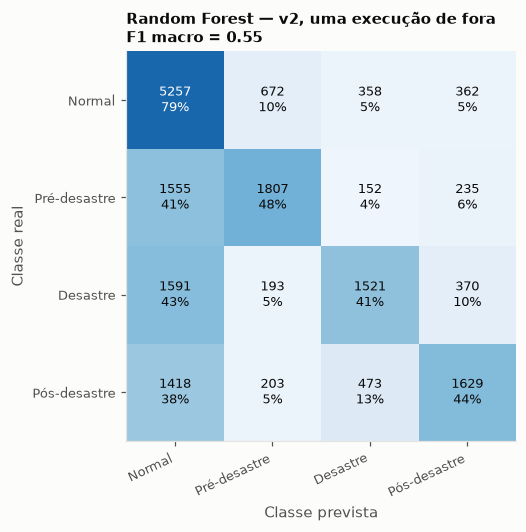

,F1,exemplos
Normal,0.638,6649
Pré-desastre,0.546,3749
Desastre,0.492,3675
Pós-desastre,0.516,3723


In [8]:
REFERENCIA = ("v2", alvo, "Random Forest")
prev = previsoes[REFERENCIA]
d2 = dados["v2"]
cm = confusion_matrix(y2[prev.index], prev, labels=CLASSES)
taxa = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5, 4.6))
ax.imshow(taxa, cmap=SEQUENCIAL, vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm[i, j]}\n{100 * taxa[i, j]:.0f}%", ha="center", va="center", fontsize=8.5,
                color="white" if taxa[i, j] > 0.55 else "#0b0b0b")
nomes = [NOMES_CLASSES[c] for c in CLASSES]
ax.set_xticks(range(4), nomes, rotation=25, ha="right", fontsize=8.5)
ax.set_yticks(range(4), nomes, fontsize=8.5)
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
ax.grid(False)
ax.set_title(f"Random Forest — v2, uma execução de fora\nF1 macro = {f1_score(y2, prev, average='macro'):.2f}", fontsize=10)
salvar(fig, "versoes_matriz_confusao_v2.png")
plt.show()

_, _, f1, suporte = precision_recall_fscore_support(y2[prev.index], prev, labels=CLASSES, zero_division=0)
pd.DataFrame({"F1": f1, "exemplos": suporte}, index=nomes).round(3)

In [9]:
# Desempenho por execução de teste e alarmes falsos na execução sem desastre.
por_exec = []
for run, idx in d2.groupby("run_id").groups.items():
    real, previsto = y2[idx], prev[idx]
    linha = {"execução": run[:11], "linhas": len(idx), "acurácia": accuracy_score(real, previsto)}
    if real.nunique() > 1:
        linha["F1 macro"] = f1_score(real, previsto, average="macro")
    linha["normal previsto como outra fase"] = ((real == "normal") & (previsto != "normal")).sum() / (real == "normal").sum()
    por_exec.append(linha)
por_exec = pd.DataFrame(por_exec).set_index("execução")
por_exec.to_csv(RESULTADOS / "versoes_desempenho_por_execucao.csv", float_format="%.4f")
por_exec.round(3)

,linhas,acurácia,F1 macro,normal previsto como outra fase
execução,,,,
execucao_01,2116,0.609,0.590,0.215
execucao_02,2301,0.490,0.496,0.156
execucao_03,1589,0.550,0.556,0.145
execucao_04,2481,0.528,0.521,0.134
execucao_05,2118,0.568,0.567,0.158
execucao_06,2437,0.505,0.493,0.072
execucao_07,2179,0.652,0.634,0.110
execucao_08,2575,0.682,NaN,0.318


In [10]:
# Acerto por papel do sensor e nas perturbações benignas (metadados de auditoria, fora do treino).
analise = d2.assign(previsto=prev, acerto=(prev == y2))
benigno = analise["event_name"].str.endswith("_benigno")
display((analise.groupby(["papel", "label"], observed=True)["acerto"].mean().unstack()
         .reindex(columns=CLASSES)).style.format("{:.0%}", na_rep="—"))
for nome, grupo in analise[benigno].groupby("event_name"):
    print(f"{nome}: {len(grupo)} consultas; classificadas como normal: {(grupo['previsto'] == 'normal').mean():.0%}")

# Quanto dos erros vem dos controles, cujas leituras não mudam com a fase.
fora_normal = analise[analise["label"] != "normal"]
controle = fora_normal["papel"] == "Controle"
print(f"Consultas fora da fase normal vindas de controles: {controle.mean():.0%}; "
      f"dessas, previstas como normal: {(fora_normal.loc[controle, 'previsto'] == 'normal').mean():.0%}")
afetados = analise[analise["papel"] != "Controle"]
print(f"F1 macro só nos sensores que não são controle (avaliação, sem retreinar): "
      f"{f1_score(afetados['label'].astype(str), afetados['previsto'], average='macro'):.2f}")

label,normal,pre_desastre,desastre,pos_desastre
papel,,,,
Controle,76%,5%,2%,3%
Degradação,84%,75%,88%,66%
Falha de rede,82%,81%,83%,71%
Falha energética,85%,86%,39%,100%


aquecimento_local_benigno: 80 consultas; classificadas como normal: 91%
congestionamento_benigno: 70 consultas; classificadas como normal: 59%
Consultas fora da fase normal vindas de controles: 43%; dessas, previstas como normal: 90%
F1 macro só nos sensores que não são controle (avaliação, sem retreinar): 0.78


**Onde o modelo de referência erra.**

- **Controles.** Os sensores de controle têm leituras normais em todas as fases e são classificados como `normal` em 90% das consultas fora da fase normal. Na v1, eles acertavam 67% a 74% por causa da bateria; na v2, só 2% a 5%. Esses sensores fornecem **43% das consultas** das fases pré-desastre, desastre e pós-desastre, o que explica a coluna `normal` da matriz de confusão. Nos sensores afetados, o F1 macro é 0,78 e menos de 4% das consultas das fases críticas são confundidas com `normal`.
- **Falha energética no desastre.** Depois do esgotamento, o sensor só responde `5.03`; uma falha no fim do desastre é igual a uma no pós-desastre (39% de acerto no desastre).
- **Alarmes falsos.** Na execução sem desastre, 32% das consultas foram classificadas como alguma fase de desastre; nas execuções com desastre, de 7% a 22% das consultas normais. Os congestionamentos benignos enganam o modelo com frequência (59% classificados como normal), enquanto os aquecimentos locais quase nunca (91%).
- **Variação entre execuções.** O F1 macro por execução vai de 0,49 a 0,63, o que mostra que o desempenho depende da configuração sorteada e que uma única execução de teste seria uma estimativa instável.

## 5. Respostas às perguntas de revisão

1. **Há exemplos suficientes em cada classe?** Sim. A v2 tem 17.812 linhas, pelo menos 3.681 por classe, distribuídas em oito execuções independentes.
2. **Os rótulos fazem sentido?** Sim quanto ao roteiro: todas as verificações passaram. Mas a v2 deixa claro um limite do rótulo de **fase global** aplicado a cada consulta: 43% das consultas das fases críticas vêm de controles, que não carregam informação sobre a fase. Classificar consultas isoladas desses sensores é impossível por construção.
3. **O cenário está fácil ou artificial demais?** A v1 estava: o nível de bateria resolvia a tarefa sozinho. A v2 removeu esse atalho e acrescentou perturbações benignas e variação entre execuções. Continuam artificiais a pressão constante e o sorteio uniforme das leituras dentro de cada faixa.
4. **Os modelos aprendem algo relevante ou uma regra trivial?** Na v1, em boa parte, uma regra trivial (bateria). Na v2, sem o atalho, o desempenho cai para 0,55, mas passa a vir de sinais ligados ao fenômeno: degradação da rede, taxa de descarga e temperatura. Nos sensores afetados, o modelo chega a 0,78.
5. **É necessário variar mais os parâmetros?** As variações atuais já mudam as conclusões. O passo mais útil agora não é variar mais, e sim **mudar a unidade de decisão**: agregar as consultas de todos os sensores de um gateway em uma janela de tempo, para que os controles deixem de contar como erros e o modelo veja o estado do ambiente, que é o que o rótulo descreve.

**Próximos passos para os experimentos finais:** usar a v2 com avaliação por execução; testar atributos de janela temporal por sensor e agregados por gateway; comparar os conjuntos de atributos com a taxa de bateria no lugar do nível; e ajustar hiperparâmetros com validação cruzada agrupada por execução.